# Phase 1 – Data Preprocessing & Leakage Prevention

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline

In [2]:
df = pd.read_csv("Rainfall.csv")

print("Dataset Shape:", df.shape)
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (366, 12)
   day  pressure   maxtemp  temparature  mintemp  dewpoint  humidity   cloud   \
0    1     1025.9     19.9         18.3     16.8      13.1         72      49   
1    2     1022.0     21.7         18.9     17.2      15.6         81      83   
2    3     1019.7     20.3         19.3     18.0      18.4         95      91   
3    4     1018.9     22.3         20.6     19.1      18.8         90      88   
4    5     1015.9     21.3         20.7     20.2      19.9         95      81   

  rainfall  sunshine           winddirection  windspeed  
0      yes       9.3                    80.0       26.3  
1      yes       0.6                    50.0       15.3  
2      yes       0.0                    40.0       14.2  
3      yes       1.0                    50.0       16.9  
4      yes       0.0                    40.0       13.7  

Missing Values:
day                       0
pressure                  0
maxtemp                   0
temparature               0
mintemp    

In [3]:

df = df.dropna(subset=["rainfall"])


df["rainfall"] = df["rainfall"].map({
    "yes": 1,
    "no": 0
})

df = df.dropna(subset=["rainfall"])

# Separate features and target
X = df.drop("rainfall", axis=1)
y = df["rainfall"].astype(int)

X = X.drop(
    columns=["maxtemp", "mintemp", "day"],
    errors="ignore"
)

print("Features:", X.columns.tolist())
print("Target Distribution:")
print(y.value_counts())

Features: ['pressure ', 'temparature', 'dewpoint', 'humidity ', 'cloud ', 'sunshine', '         winddirection', 'windspeed']
Target Distribution:
rainfall
1    249
0    117
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (292, 8)
Testing Data: (74, 8)


In [5]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("oversampler", RandomOverSampler(random_state=42)),

    ("classifier", LogisticRegression(max_iter=1000))
])

In [6]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [7]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

In [8]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8243243243243243
Precision: 0.8775510204081632
Recall: 0.86
F1 Score: 0.8686868686868687
ROC-AUC: 0.9233333333333333

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.75      0.73        24
           1       0.88      0.86      0.87        50

    accuracy                           0.82        74
   macro avg       0.80      0.80      0.80        74
weighted avg       0.83      0.82      0.83        74


Confusion Matrix:
[[18  6]
 [ 7 43]]


# Phase 2 – Multiple Machine Learning Algorithms

In [9]:
import pandas as pd
import numpy as np

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    )
}

In [11]:
results = []
trained_models = {}

for name, classifier in models.items():

    pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),

        ("scaler", StandardScaler()),

        ("oversampler", RandomOverSampler(random_state=42)),

        ("classifier", classifier)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)

    # Prediction probabilities
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Evaluation
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

    trained_models[name] = pipeline

    print(f"{name} completed!")

Logistic Regression completed!
Decision Tree completed!
Random Forest completed!
KNN completed!
SVM completed!


In [12]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

print(results_df.round(4))

             Algorithm  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression    0.8243     0.8776    0.86    0.8687   0.9233
4                  SVM    0.7973     0.8571    0.84    0.8485   0.9188
2        Random Forest    0.8108     0.8600    0.86    0.8600   0.8725
3                  KNN    0.7432     0.8444    0.76    0.8000   0.7946
1        Decision Tree    0.7027     0.7692    0.80    0.7843   0.6500


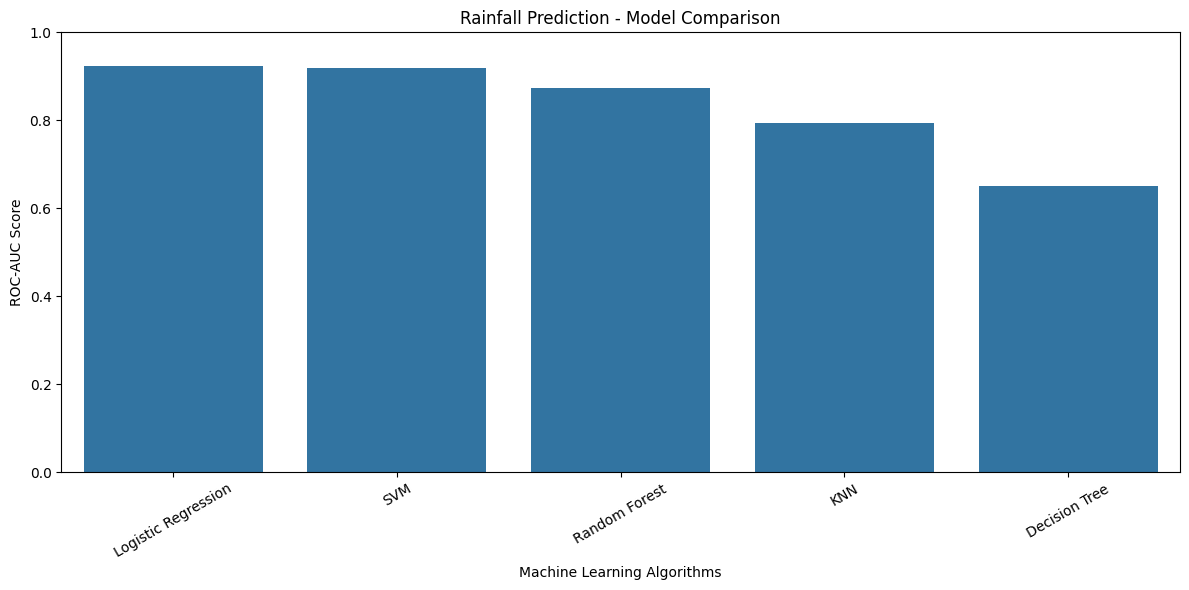

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="ROC-AUC"
)

plt.title("Rainfall Prediction - Model Comparison")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("ROC-AUC Score")

plt.xticks(rotation=30)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [14]:
best_model_name = results_df.iloc[0]["Algorithm"]

best_model = trained_models[best_model_name]

print("Best Candidate:", best_model_name)

print("\nPerformance:")
print(
    results_df.iloc[0]
)

Best Candidate: Logistic Regression

Performance:
Algorithm    Logistic Regression
Accuracy                0.824324
Precision               0.877551
Recall                      0.86
F1 Score                0.868687
ROC-AUC                 0.923333
Name: 0, dtype: object


In [15]:
from sklearn.metrics import classification_report, confusion_matrix

best_predictions = best_model.predict(X_test)

print("Classification Report:")

print(
    classification_report(
        y_test,
        best_predictions
    )
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_test,
        best_predictions
    )
)

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.75      0.73        24
           1       0.88      0.86      0.87        50

    accuracy                           0.82        74
   macro avg       0.80      0.80      0.80        74
weighted avg       0.83      0.82      0.83        74

Confusion Matrix:
[[18  6]
 [ 7 43]]


# Phase 3: Hyperparameter Tuning & Cross-Validation

## Objective
The objective of this phase is to improve machine learning model performance by finding optimal hyperparameters and evaluating model consistency through cross-validation.

## Steps Performed

1. Apply Stratified K-Fold Cross-Validation.
2. Perform hyperparameter tuning using GridSearchCV.
3. Tune Random Forest parameters.
4. Identify the best hyperparameter combination.
5. Train the optimized model.
6. Evaluate the final model using classification metrics.

## Techniques Used

- K-Fold Cross-Validation
- StratifiedKFold
- GridSearchCV
- Random Forest Classifier
- ROC-AUC
- Classification Report
- Confusion Matrix

## Expected Outcome

An optimized Random Forest model with improved and more reliable evaluation.

In [16]:
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [17]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [18]:
rf_pipeline = Pipeline(steps=[

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("oversampler", RandomOverSampler(random_state=42)),

    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight=None
    ))

])

In [19]:
param_grid = {

    "classifier__n_estimators": [100, 200, 300],

    "classifier__max_depth": [None, 5, 10, 15],

    "classifier__min_samples_split": [2, 5, 10],

    "classifier__min_samples_leaf": [1, 2, 4],

    "classifier__max_features": ["sqrt", "log2"]

}

In [20]:
grid_search = GridSearchCV(

    estimator=rf_pipeline,

    param_grid=param_grid,

    scoring="roc_auc",

    cv=cv,

    n_jobs=-1,

    verbose=1

)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'classifier__max_depth': [None, 5, ...], 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], ...}"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,missing_values,nan


In [21]:
print("Best Parameters:")

print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")

print(grid_search.best_score_)

Best Parameters:
{'classifier__max_depth': 5, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}

Best Cross-Validation ROC-AUC:
0.8464417453891139


In [22]:
best_rf_model = grid_search.best_estimator_

print("Optimized Random Forest Model:")
print(best_rf_model)

Optimized Random Forest Model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('oversampler', RandomOverSampler(random_state=42)),
                ('classifier',
                 RandomForestClassifier(max_depth=5, min_samples_split=5,
                                        random_state=42))])


In [23]:
y_pred = best_rf_model.predict(X_test)

y_prob = best_rf_model.predict_proba(X_test)[:, 1]

In [24]:
print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))

Accuracy: 0.8108108108108109
Precision: 0.8913043478260869
Recall: 0.82
F1 Score: 0.8541666666666666
ROC-AUC: 0.8891666666666667


In [25]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Rain", "Rain"]
    )
)

              precision    recall  f1-score   support

     No Rain       0.68      0.79      0.73        24
        Rain       0.89      0.82      0.85        50

    accuracy                           0.81        74
   macro avg       0.78      0.81      0.79        74
weighted avg       0.82      0.81      0.81        74



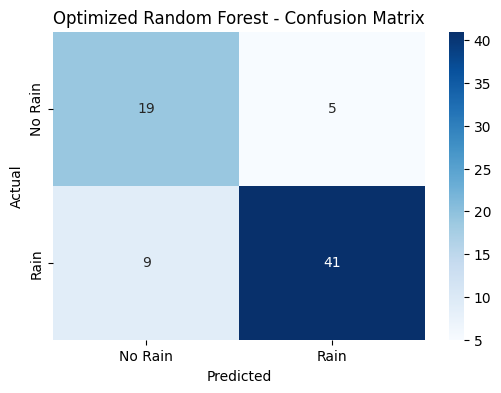

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Rain", "Rain"],
    yticklabels=["No Rain", "Rain"]
)

plt.title("Optimized Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [27]:
original_rf = trained_models["Random Forest"]

original_pred = original_rf.predict(X_test)

original_prob = original_rf.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({

    "Model": [
        "Original Random Forest",
        "Optimized Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, original_pred),
        accuracy_score(y_test, y_pred)
    ],

    "F1 Score": [
        f1_score(y_test, original_pred),
        f1_score(y_test, y_pred)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, original_prob),
        roc_auc_score(y_test, y_prob)
    ]

})

print(comparison.round(4))

                     Model  Accuracy  F1 Score  ROC-AUC
0   Original Random Forest    0.8108    0.8600   0.8725
1  Optimized Random Forest    0.8108    0.8542   0.8892


# Phase 4: Feature Importance & Model Explainability

## Objective

The objective of this phase is to understand which weather features contribute most to the rainfall prediction model.

## Steps Performed

1. Extract feature importance from the optimized Random Forest model.
2. Rank weather features according to their importance.
3. Visualize the top contributing features.
4. Apply Permutation Importance to evaluate feature contributions.
5. Compare both feature importance techniques.

## Techniques Used

* Random Forest Feature Importance
* Permutation Importance
* Pandas
* Matplotlib
* Seaborn
* Scikit-learn

## Expected Outcome

Identify the most influential weather features and improve the interpretability of the rainfall prediction model.


In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


rf_model = best_rf_model.named_steps["classifier"]


feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})


feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)


print("Random Forest Feature Importance:")
display(feature_importance)

Random Forest Feature Importance:


,Feature,Importance
4,cloud,0.286598
5,sunshine,0.273109
3,humidity,0.124936
2,dewpoint,0.073740
1,temparature,0.071641
7,windspeed,0.070542
0,pressure,0.069073
6,winddirection,0.030362


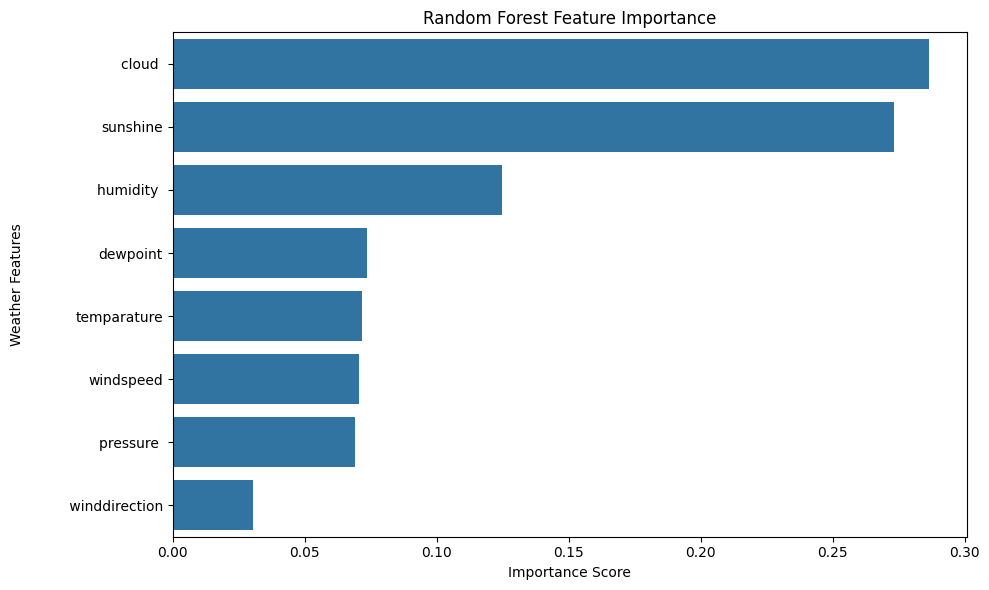

In [29]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Weather Features")
plt.tight_layout()
plt.show()

In [30]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
perm_importance = permutation_importance(
    best_rf_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

# Create DataFrame
permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_importance.importances_mean,
    "Std": perm_importance.importances_std
})

# Sort results
permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

display(permutation_df)

,Feature,Importance,Std
4,cloud,0.107611,0.033752
5,sunshine,0.068694,0.019979
3,humidity,0.035028,0.011948
2,dewpoint,0.006111,0.015004
6,winddirection,0.002806,0.002683
7,windspeed,0.002222,0.006709
1,temparature,-0.001861,0.006073
0,pressure,-0.010194,0.009958


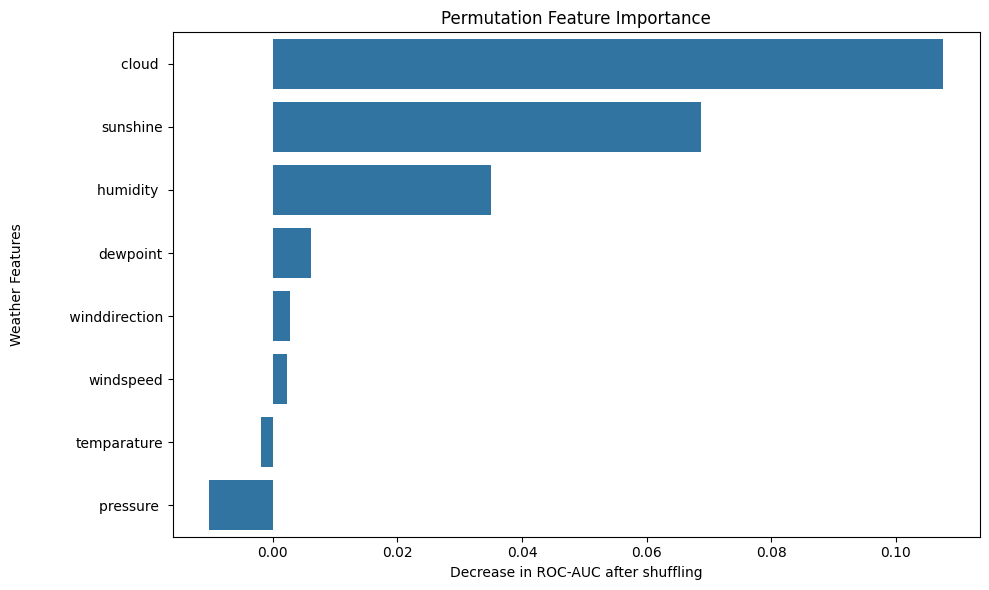

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=permutation_df,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in ROC-AUC after shuffling")
plt.ylabel("Weather Features")
plt.tight_layout()
plt.show()

In [32]:
importance_comparison = feature_importance.merge(
    permutation_df,
    on="Feature",
    suffixes=("_RF", "_Permutation")
)

importance_comparison = importance_comparison.sort_values(
    by="Importance_Permutation",
    ascending=False
)

display(importance_comparison)

,Feature,Importance_RF,Importance_Permutation,Std
0,cloud,0.286598,0.107611,0.033752
1,sunshine,0.273109,0.068694,0.019979
2,humidity,0.124936,0.035028,0.011948
3,dewpoint,0.073740,0.006111,0.015004
7,winddirection,0.030362,0.002806,0.002683
5,windspeed,0.070542,0.002222,0.006709
4,temparature,0.071641,-0.001861,0.006073
6,pressure,0.069073,-0.010194,0.009958


# Phase 5: Final Model Evaluation & Model Saving

## Objective

The objective of this phase is to evaluate the optimized Random Forest model using different classification metrics and save the trained model for future use.

## Steps Performed

1. Generate predictions using the optimized Random Forest model.
2. Calculate accuracy, precision, recall, F1-score and ROC-AUC.
3. Generate a classification report.
4. Visualize the confusion matrix.
5. Plot the ROC curve.
6. Save the trained machine learning pipeline using Joblib.

## Evaluation Metrics

* Accuracy
* Precision
* Recall
* F1-Score
* ROC-AUC

## Tools and Libraries

* Scikit-learn
* Pandas
* Matplotlib
* Seaborn
* Joblib

## Expected Outcome

A thoroughly evaluated and saved Random Forest machine learning pipeline ready for integration into a prediction application.


In [33]:
# Generate predictions
final_predictions = best_rf_model.predict(X_test)

# Generate prediction probabilities
final_probabilities = best_rf_model.predict_proba(X_test)[:, 1]

print("Final predictions generated successfully!")

Final predictions generated successfully!


In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculate metrics
accuracy = accuracy_score(y_test, final_predictions)

precision = precision_score(y_test, final_predictions)

recall = recall_score(y_test, final_predictions)

f1 = f1_score(y_test, final_predictions)

roc_auc = roc_auc_score(y_test, final_probabilities)

# Display results
print("FINAL MODEL PERFORMANCE")
print("-----------------------")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

FINAL MODEL PERFORMANCE
-----------------------
Accuracy:  0.8108
Precision: 0.8913
Recall:    0.8200
F1 Score:  0.8542
ROC-AUC:   0.8892


In [35]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["No Rainfall", "Rainfall"]
    )
)

Classification Report:

              precision    recall  f1-score   support

 No Rainfall       0.68      0.79      0.73        24
    Rainfall       0.89      0.82      0.85        50

    accuracy                           0.81        74
   macro avg       0.78      0.81      0.79        74
weighted avg       0.82      0.81      0.81        74



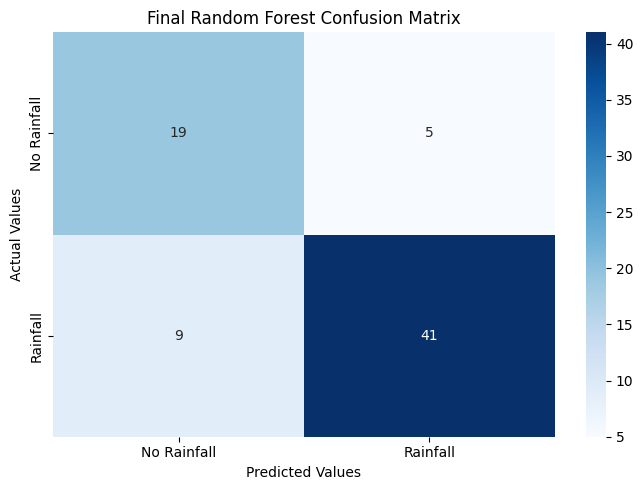

In [36]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Rainfall", "Rainfall"],
    yticklabels=["No Rainfall", "Rainfall"]
)

plt.title("Final Random Forest Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.tight_layout()
plt.show()

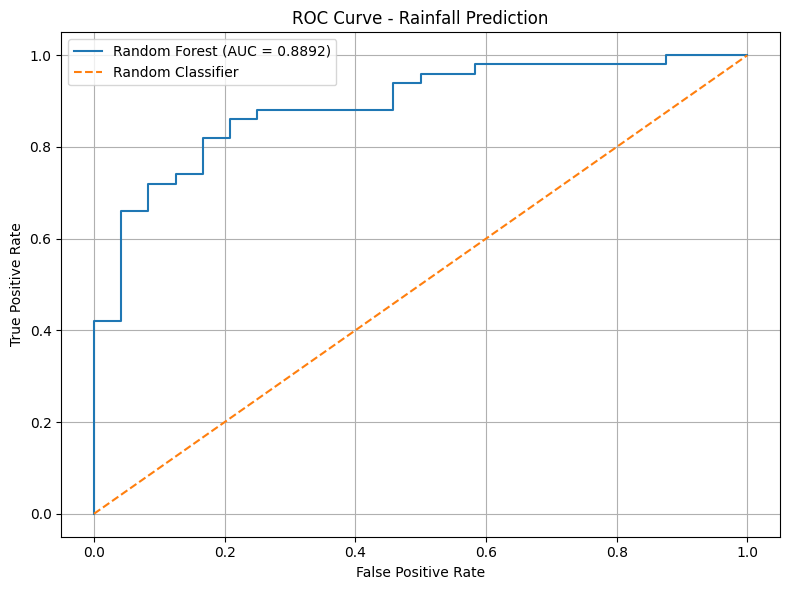

In [37]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(
    y_test,
    final_probabilities
)

roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc_value:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Rainfall Prediction")

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [38]:
import joblib
import os

# Create models folder
os.makedirs("models", exist_ok=True)

# Save complete trained pipeline
joblib.dump(
    best_rf_model,
    "models/rainfall_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [39]:
loaded_model = joblib.load(
    "models/rainfall_model.pkl"
)

sample_predictions = loaded_model.predict(X_test.head(5))

print("Sample Predictions:")

for prediction in sample_predictions:
    if prediction == 1:
        print("Rainfall: YES")
    else:
        print("Rainfall: NO")

Sample Predictions:
Rainfall: NO
Rainfall: YES
Rainfall: YES
Rainfall: YES
Rainfall: NO
